# Практика 1.1. Линейная регрессия

**Задача:** предсказать почасовую выработку электроэнергии парогазовой электростанции по погодным условиям.

**Датасет:** [Combined Cycle Power Plant (UCI)](https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant) — 9 568 почасовых наблюдений (2006–2011 гг.), станция работала на полной нагрузке.

| Признак | Описание |
|---|---|
| `temperature` (AT) | температура воздуха, °C |
| `exhaust_vacuum` (V) | разрежение в выхлопе паровой турбины, см рт. ст. |
| `ambient_pressure` (AP) | атмосферное давление, мбар |
| `relative_humidity` (RH) | относительная влажность, % |
| **`energy_output` (PE)** | **целевая переменная** — выработка, МВт |

**План:** загрузка → проверка качества данных (пропуски, дубликаты, аномалии) → EDA → разбиение train/val/test → обучение и выбор модели на валидации → финальная оценка на тесте.

## 0. Зависимости и импорты

In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn mlflow openpyxl

In [2]:
import io
import zipfile
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

## 1. Настройки и вспомогательные функции

In [3]:
EXPERIMENT_NAME = "p1_linear_regression"
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00294/CCPP.zip"
TARGET = "energy_output"
COLUMN_NAMES = {
    "AT": "temperature",
    "V": "exhaust_vacuum",
    "AP": "ambient_pressure",
    "RH": "relative_humidity",
    "PE": TARGET,
}


SEED = 42
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
MLFLOW_URI = f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}"

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENT_NAME)


def download(url, filename):
    path = DATA_DIR / filename
    if not path.exists():
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        urlretrieve(url, path)
    return path


def quality_report(frame):
    return pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "missing": frame.isna().sum(),
        "missing_%": (frame.isna().mean() * 100).round(2),
        "unique": frame.nunique(),
    })


def iqr_outlier_mask(frame, k=1.5):
    q1, q3 = frame.quantile(0.25), frame.quantile(0.75)
    iqr = q3 - q1
    return (frame < q1 - k * iqr) | (frame > q3 + k * iqr)


def regression_metrics(y_true, y_pred):
    return {
        "mae": mean_absolute_error(y_true, y_pred),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "r2": r2_score(y_true, y_pred),
    }

2026/11/10 13:23:49 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/10 13:23:49 INFO mlflow.store.db.utils: Updating database tables
2026/11/10 13:23:53 INFO mlflow.tracking.fluent: Experiment with name 'p1_linear_regression' does not exist. Creating a new experiment.


**Трекинг экспериментов.** Все запуски логируются в MLflow (база `mlflow.db` в корне репозитория).
Посмотреть результаты: из корня репозитория выполнить `mlflow ui --backend-store-uri sqlite:///mlflow.db` и открыть http://127.0.0.1:5000.

## 2. Загрузка данных
Архив скачивается один раз и кэшируется в папке `data/`. Внутри — Excel-файл с пятью листами, содержащими одни и те же данные в разном порядке, поэтому берём только первый лист.

In [4]:
zip_path = download(DATA_URL, "CCPP.zip")
with zipfile.ZipFile(zip_path) as archive:
    xlsx_name = next(name for name in archive.namelist() if name.endswith(".xlsx"))
    raw = pd.read_excel(io.BytesIO(archive.read(xlsx_name)), sheet_name=0)

df = raw.rename(columns=COLUMN_NAMES)
print(f"Размер: {df.shape[0]} строк × {df.shape[1]} столбцов")
df.head()

Размер: 9568 строк × 5 столбцов


,temperature,exhaust_vacuum,ambient_pressure,relative_humidity,energy_output
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


In [5]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9568 entries, 0 to 9567
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   temperature        9568 non-null   float64
 1   exhaust_vacuum     9568 non-null   float64
 2   ambient_pressure   9568 non-null   float64
 3   relative_humidity  9568 non-null   float64
 4   energy_output      9568 non-null   float64
dtypes: float64(5)
memory usage: 373.9 KB


,count,mean,std,min,25%,50%,75%,max
temperature,9568.0,19.651231,7.452473,1.81,13.5100,20.345,25.72,37.11
exhaust_vacuum,9568.0,54.305804,12.707893,25.36,41.7400,52.080,66.54,81.56
ambient_pressure,9568.0,1013.259078,5.938784,992.89,1009.1000,1012.940,1017.26,1033.30
relative_humidity,9568.0,73.308978,14.600269,25.56,63.3275,74.975,84.83,100.16
energy_output,9568.0,454.365009,17.066995,420.26,439.7500,451.550,468.43,495.76


## 3. Качество данных
### 3.1. Типы, пропуски, «битые» значения
Сначала ищем текстовые (нечисловые) столбцы — их пришлось бы кодировать в числа. В этом датасете все признаки — физические измерения, поэтому текстовых категорий быть не должно, и **кодирование не требуется**. На случай «битых» ячеек (например, `"n/a"` в числовом столбце) принудительно приводим всё к числу: такой текст превратится в `NaN` и будет учтён как пропуск.

In [6]:
text_cols = df.select_dtypes(exclude="number").columns.tolist()
print(f"Текстовых столбцов: {text_cols if text_cols else 'нет — кодирование не требуется'}")
df = df.apply(pd.to_numeric, errors="coerce")
quality_report(df)

Текстовых столбцов: нет — кодирование не требуется


,dtype,missing,missing_%,unique
temperature,float64,0,0.0,2773
exhaust_vacuum,float64,0,0.0,634
ambient_pressure,float64,0,0.0,2517
relative_humidity,float64,0,0.0,4546
energy_output,float64,0,0.0,4836


Стратегия для пропусков: пропуск в целевой переменной — строка удаляется (обучаться не на чем); пропуски в признаках — заполняются медианой (медиана устойчива к выбросам). Заполнение выполняется внутри `Pipeline` (`SimpleImputer`), чтобы медиана считалась только по обучающей выборке и не было утечки данных из теста.

In [7]:
before = len(df)
df = df.dropna(subset=[TARGET])
feature_cols = [c for c in df.columns if c != TARGET]
print(f"Удалено строк без целевой переменной: {before - len(df)}")
print(f"Пропусков в признаках (будут заполнены медианой в Pipeline): {df[feature_cols].isna().sum().sum()}")

Удалено строк без целевой переменной: 0
Пропусков в признаках (будут заполнены медианой в Pipeline): 0


### 3.2. Дубликаты

In [8]:
n_duplicates = df.duplicated().sum()
print(f"Полных дубликатов: {n_duplicates} ({n_duplicates / len(df):.2%})")
df = df.drop_duplicates().reset_index(drop=True)
print(f"После удаления: {len(df)} строк")

Полных дубликатов: 41 (0.43%)
После удаления: 9527 строк


### 3.3. Аномалии
Проверяем два вида аномалий:
1. **Физически невозможные значения** — влажность вне 0–100 %, давление вне разумного диапазона 900–1100 мбар, отрицательная выработка.
2. **Статистические выбросы** по правилу межквартильного размаха (IQR): значение за пределами `[Q1 − k·IQR; Q3 + k·IQR]`.

In [9]:
physical_bounds = {
    "relative_humidity": (0, 100),
    "ambient_pressure": (900, 1100),
    "temperature": (-50, 60),
    TARGET: (0, None),
}
invalid = pd.Series(False, index=df.index)
for col, (low, high) in physical_bounds.items():
    col_invalid = df[col].lt(low) if low is not None else pd.Series(False, index=df.index)
    if high is not None:
        col_invalid |= df[col].gt(high)
    print(f"{col:>20}: вне физических границ — {col_invalid.sum()}")
    invalid |= col_invalid

   relative_humidity: вне физических границ — 55
    ambient_pressure: вне физических границ — 0
         temperature: вне физических границ — 0
       energy_output: вне физических границ — 0


In [10]:
outliers_15 = iqr_outlier_mask(df).sum()
outliers_30 = iqr_outlier_mask(df, k=3).sum()
pd.DataFrame({"IQR k=1.5": outliers_15, "IQR k=3 (экстремальные)": outliers_30})

,IQR k=1.5,IQR k=3 (экстремальные)
temperature,0,0
exhaust_vacuum,0,0
ambient_pressure,91,0
relative_humidity,13,0
energy_output,0,0


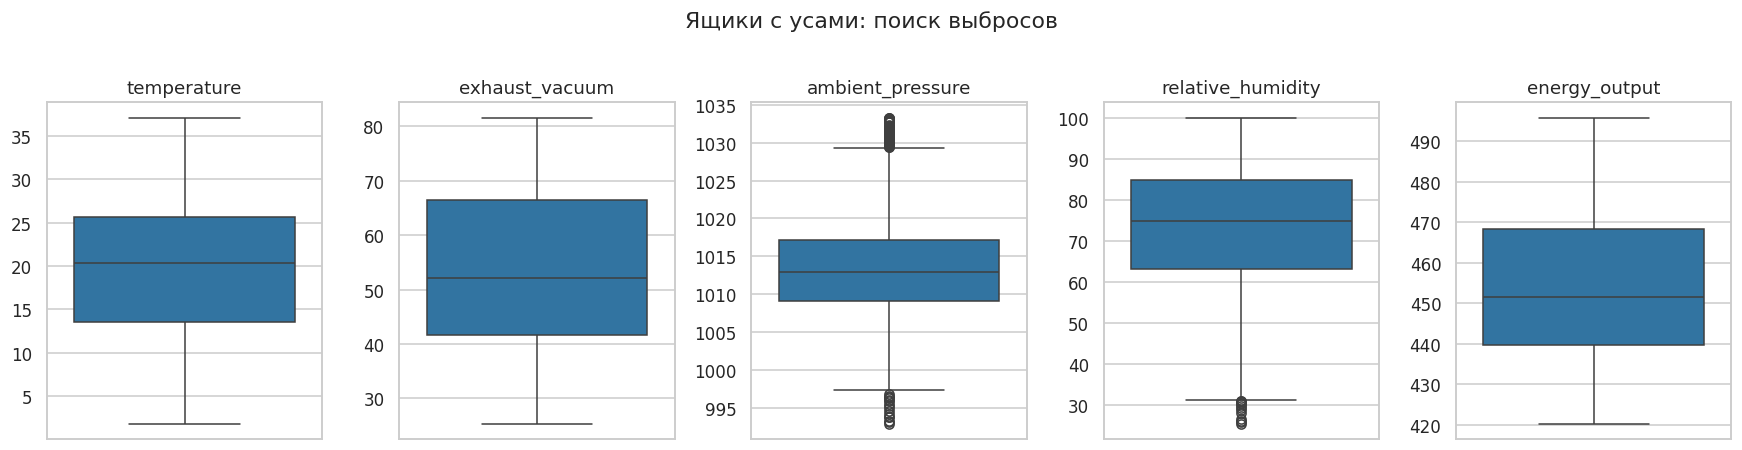

In [11]:
fig, axes = plt.subplots(1, df.shape[1], figsize=(16, 4))
for ax, col in zip(axes, df.columns):
    sns.boxplot(y=df[col], ax=ax, color="tab:blue")
    ax.set_title(col)
    ax.set_ylabel("")
fig.suptitle("Ящики с усами: поиск выбросов", y=1.02)
plt.tight_layout()
plt.show()

**Стратегия:** строки с физически невозможными значениями удаляем. Умеренные IQR-выбросы (k = 1.5) — это реальные, хотя и редкие погодные условия, поэтому их оставляем; удаляем только экстремальные (k = 3), которые с большой вероятностью являются ошибками измерения.

In [12]:
extreme = iqr_outlier_mask(df, k=3).any(axis=1)
to_drop = invalid | extreme
df = df.loc[~to_drop].reset_index(drop=True)
print(f"Удалено аномальных строк: {to_drop.sum()}; итоговый размер: {df.shape}")

Удалено аномальных строк: 55; итоговый размер: (9472, 5)


## 4. Разведочный анализ (EDA)
### 4.1. Распределения признаков

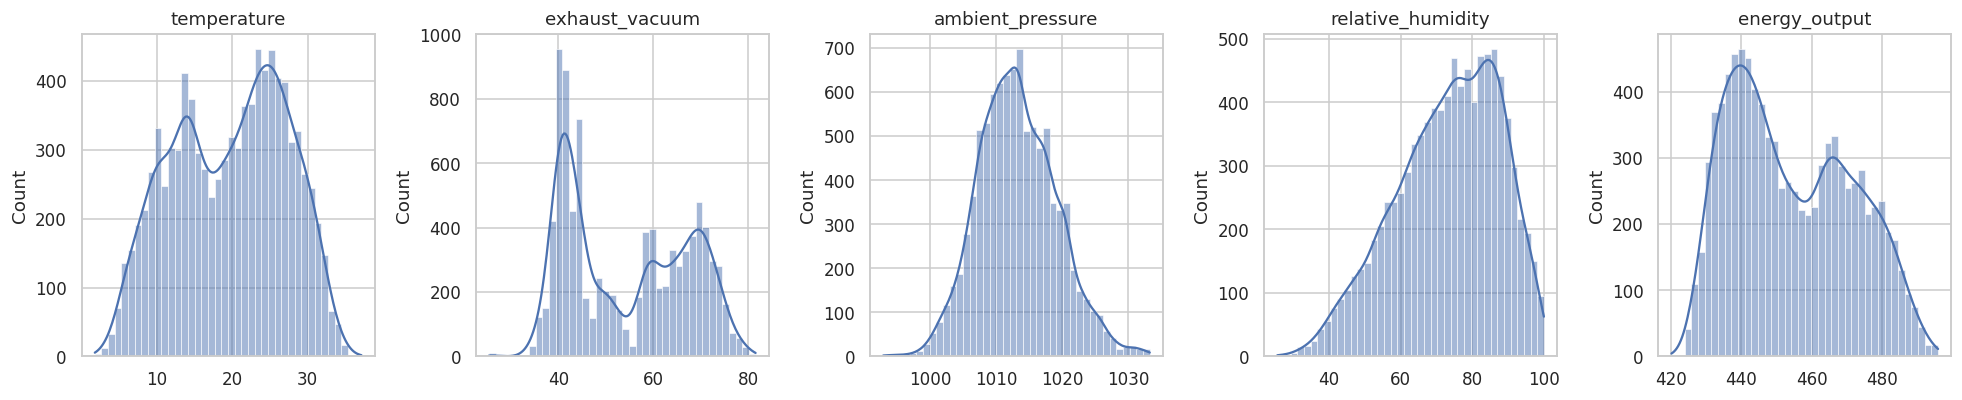

In [13]:
fig, axes = plt.subplots(1, df.shape[1], figsize=(18, 3.8))
for ax, col in zip(axes, df.columns):
    sns.histplot(df[col], kde=True, ax=ax, bins=40)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

### 4.2. Матрица корреляции

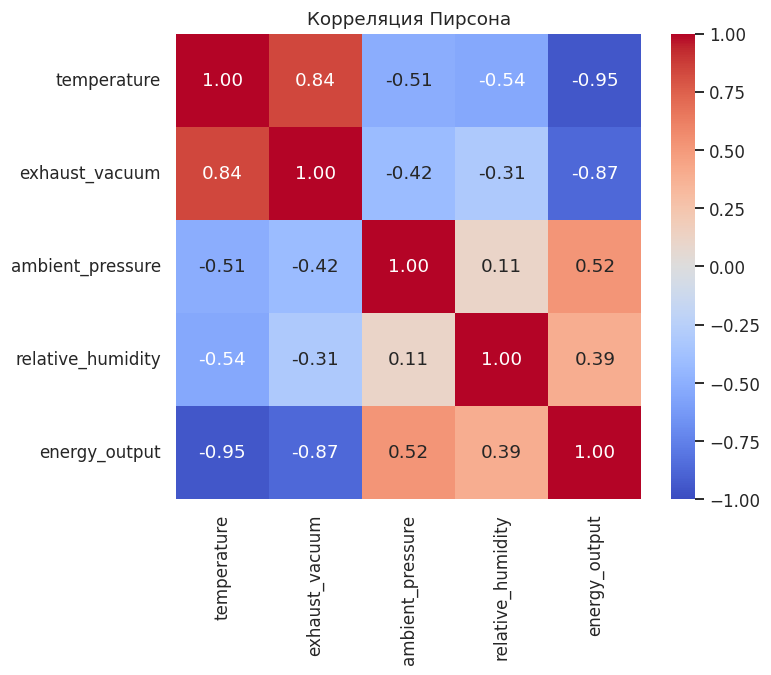

,energy_output
temperature,-0.948192
exhaust_vacuum,-0.870349
ambient_pressure,0.520575
relative_humidity,0.393257


In [14]:
corr = df.corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Корреляция Пирсона")
plt.show()
corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)

### 4.3. Связь признаков с целевой переменной

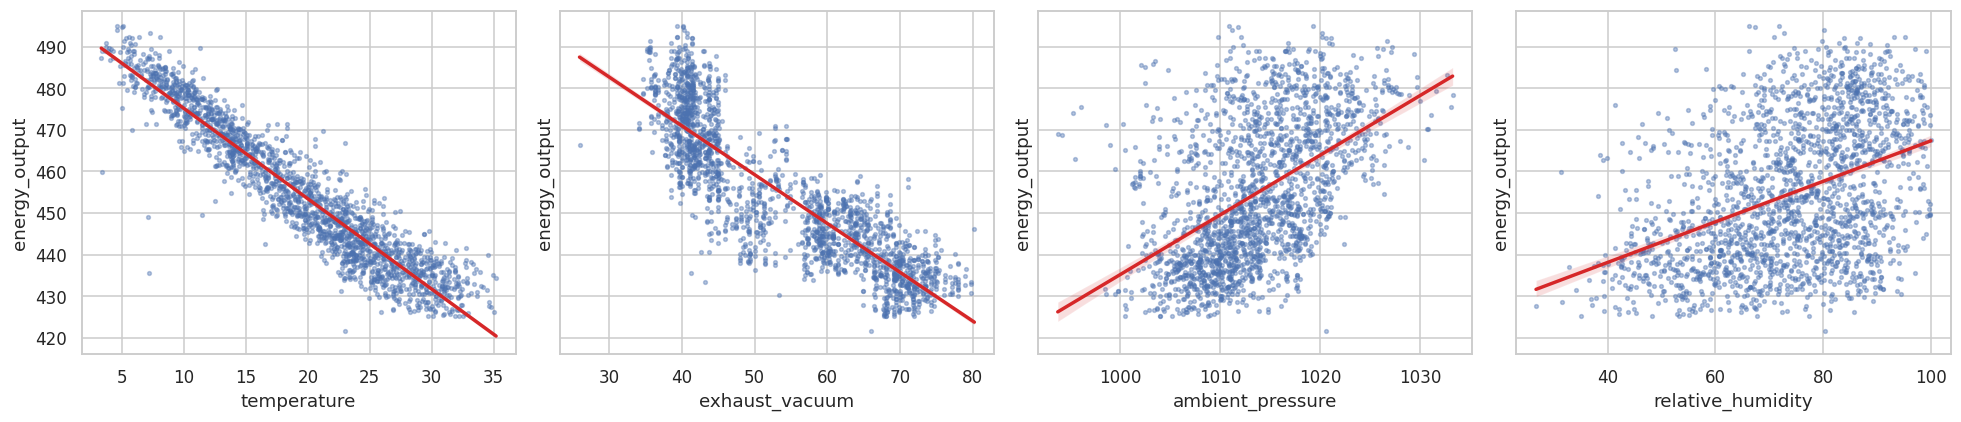

In [15]:
sample = df.sample(min(2000, len(df)), random_state=SEED)
fig, axes = plt.subplots(1, len(feature_cols), figsize=(18, 4), sharey=True)
for ax, col in zip(axes, feature_cols):
    sns.regplot(data=sample, x=col, y=TARGET, ax=ax,
                scatter_kws={"s": 6, "alpha": 0.4}, line_kws={"color": "tab:red"})
plt.tight_layout()
plt.show()

**Наблюдения EDA:**
- температура (корреляция с выработкой −0,95) и разрежение в выхлопе (−0,87) сильно и **отрицательно** связаны с выработкой, связь почти линейная — линейная регрессия хорошо подходит для задачи;
- давление (0,52) и влажность (0,39) связаны с целью заметно слабее;
- `temperature` и `exhaust_vacuum` коррелируют между собой (0,84), температура также связана с давлением (−0,51) и влажностью (−0,54) — это **мультиколлинеарность**: на точность прогноза она почти не влияет, но коэффициенты модели нужно интерпретировать осторожно;
- распределения признаков без длинных хвостов; у температуры, разрежения и выработки по два «горба» — холодный и тёплый сезоны.

## 5. Разбиение выборки
Схема **60 / 20 / 20**: на train модель обучается, на validation выбираем вариант модели, test используется **один раз** для финальной честной оценки.

In [16]:
X = df[feature_cols]
y = df[TARGET]

X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=SEED)
print(f"train: {len(X_train)}, val: {len(X_val)}, test: {len(X_test)}")

train: 5682, val: 1895, test: 1895


## 6. Обучение и выбор модели
Сравниваем два варианта:
- **`linear`** — классическая линейная регрессия на стандартизированных признаках;
- **`poly2`** — линейная регрессия на полиномиальных признаках 2-й степени (квадраты и попарные произведения). Модель остаётся линейной по параметрам, но может описать небольшую нелинейность.

`SimpleImputer` и `StandardScaler` находятся внутри `Pipeline`, поэтому медианы и параметры масштабирования вычисляются только по обучающей выборке — без утечки данных. Дополнительно считаем 5-кратную кросс-валидацию на train, чтобы оценить стабильность.

In [17]:
candidates = {
    "linear": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()),
    "poly2": make_pipeline(SimpleImputer(strategy="median"), PolynomialFeatures(degree=2, include_bias=False),
                           StandardScaler(), LinearRegression()),
}
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

val_results = {}
for name, model in candidates.items():
    cv_rmse = -cross_val_score(model, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    model.fit(X_train, y_train)
    metrics = regression_metrics(y_val, model.predict(X_val))
    metrics["cv_rmse_mean"], metrics["cv_rmse_std"] = cv_rmse.mean(), cv_rmse.std()
    val_results[name] = metrics
    with mlflow.start_run(run_name=f"{name}_validation"):
        mlflow.log_params({"model": name, "n_train": len(X_train), "seed": SEED})
        mlflow.log_metrics({f"val_{k}": v for k, v in metrics.items()})

val_table = pd.DataFrame(val_results).T
val_table

,mae,rmse,r2,cv_rmse_mean,cv_rmse_std
linear,3.628410,4.435762,0.933423,4.596591,0.092776
poly2,3.359132,4.141181,0.941972,4.279727,0.124419


In [18]:
best_name = val_table["rmse"].idxmin()
print(f"Лучшая модель по RMSE на валидации: {best_name}")

Лучшая модель по RMSE на валидации: poly2


## 7. Финальная оценка на тестовой выборке
Лучшую модель переобучаем на train + val (больше данных — точнее оценка параметров) и один раз оцениваем на test.

In [19]:
final_model = candidates[best_name]
final_model.fit(X_train_full, y_train_full)
y_pred = final_model.predict(X_test)
test_metrics = regression_metrics(y_test, y_pred)
train_metrics = regression_metrics(y_train_full, final_model.predict(X_train_full))
pd.DataFrame({"train+val": train_metrics, "test": test_metrics}).T

,mae,rmse,r2
train+val,3.363519,4.233118,0.938713
test,3.348629,4.392862,0.932975


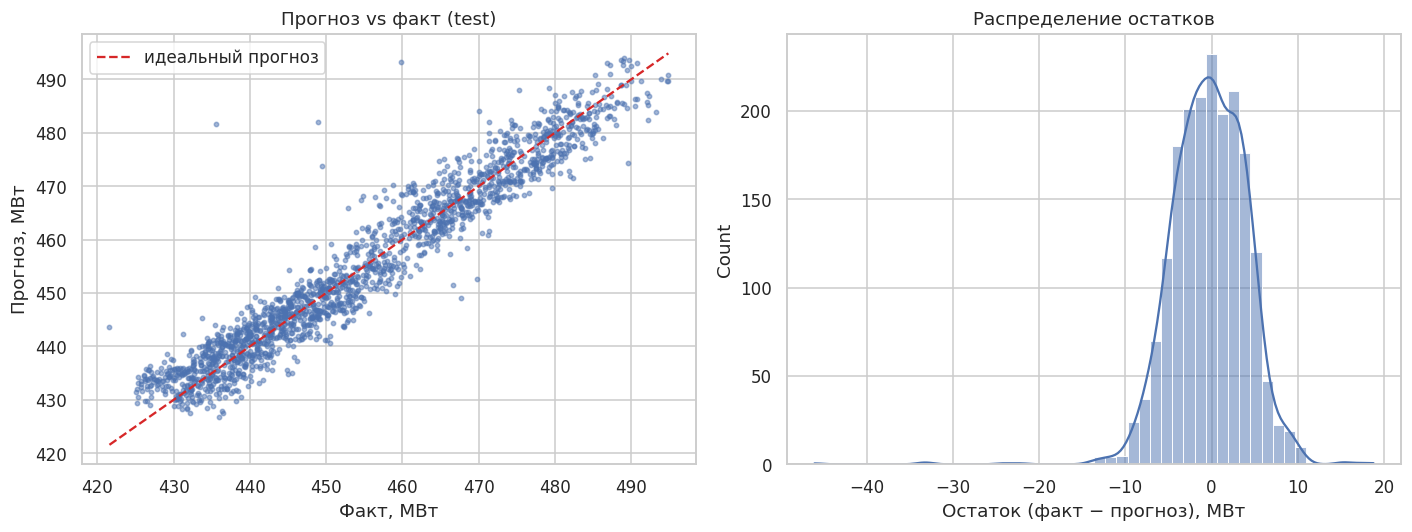

In [20]:
residuals = y_test - y_pred
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, y_pred, s=8, alpha=0.5)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, color="tab:red", linestyle="--", label="идеальный прогноз")
axes[0].set(xlabel="Факт, МВт", ylabel="Прогноз, МВт", title="Прогноз vs факт (test)")
axes[0].legend()
sns.histplot(residuals, kde=True, ax=axes[1], bins=50)
axes[1].set(xlabel="Остаток (факт − прогноз), МВт", title="Распределение остатков")
plt.tight_layout()
plt.show()

### Интерпретация базовой линейной модели
Коэффициенты линейной модели на стандартизированных признаках показывают, на сколько МВт меняется прогноз при изменении признака на одно стандартное отклонение.

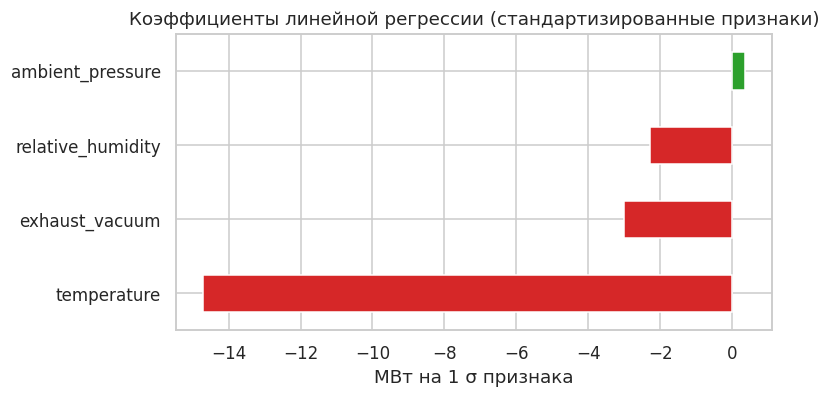

Свободный член: 454.25 МВт


In [21]:
linear_model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()).fit(X_train_full, y_train_full)
coefs = pd.Series(linear_model[-1].coef_, index=feature_cols).sort_values()
coefs.plot.barh(figsize=(7, 3.5), color=np.where(coefs > 0, "tab:green", "tab:red"))
plt.title("Коэффициенты линейной регрессии (стандартизированные признаки)")
plt.xlabel("МВт на 1 σ признака")
plt.show()
print(f"Свободный член: {linear_model[-1].intercept_:.2f} МВт")

In [22]:
with mlflow.start_run(run_name=f"{best_name}_final"):
    mlflow.log_params({"model": best_name, "n_train": len(X_train_full), "seed": SEED})
    mlflow.log_metrics({f"test_{k}": v for k, v in test_metrics.items()})
    mlflow.log_metrics({f"train_{k}": v for k, v in train_metrics.items()})
    mlflow.log_figure(fig, "pred_vs_true_and_residuals.png")
print("Финальный запуск записан в MLflow")

Финальный запуск записан в MLflow


## 8. Выводы
- **Качество данных.** Текстовых столбцов и пропусков в 9 568 наблюдениях нет, кодирование не потребовалось. Удалён 41 полный дубликат (0,43 %) и 55 строк с влажностью выше 100 % — физически невозможное значение, ошибка датчика. Умеренные IQR-выбросы (91 в давлении, 13 во влажности) оставлены как реальные погодные условия; экстремальных выбросов (k = 3) нет. Итог — 9 472 наблюдения.
- **Выбор модели.** На валидации полиномиальный вариант `poly2` точнее чистой линейной модели: RMSE 4,14 против 4,44 МВт, R² 0,942 против 0,933; кросс-валидация подтверждает это (RMSE 4,28 ± 0,12 против 4,60 ± 0,09). Это по-прежнему **линейная регрессия** — линейная по параметрам, но на признаках, дополненных квадратами и попарными произведениями, что позволяет учесть небольшую нелинейность.
- **Итог на тесте (1 895 наблюдений):** MAE **3,35 МВт**, RMSE **4,39 МВт**, R² **0,933** — модель объясняет 93 % разброса выработки. При выработке 420–495 МВт средняя ошибка составляет менее 1 %. RMSE на train + val (4,23) почти равна тестовой — переобучения нет.
- **Остатки** симметричны относительно нуля и в основном лежат в пределах ±10 МВт; единичные большие ошибки (до −45 МВт) — вероятно, нештатные режимы работы станции, которые погодой не объясняются.
- **Интерпретация** (коэффициенты линейной модели на стандартизированных признаках): главный фактор — **температура**: рост на одно стандартное отклонение (≈ 7,5 °C) снижает выработку на ≈ 14,7 МВт (горячий воздух менее плотный, турбина менее эффективна). Влияние разрежения (−3 МВт) и влажности (−2,3 МВт) существенно меньше. У давления коэффициент близок к нулю, хотя корреляция с целью 0,52: его связь с выработкой в основном объясняется тем, что давление коррелирует с температурой. Это наглядное проявление мультиколлинеарности.